# 03 · Risoluzione in funzione delle dimensioni delle barre triangolari

**Setup dello scan** (`scripts/scan_bars.sh`, risultati in `~/runs/scan_bars`):

* rivelatore completo, configurazione PERPENDICULAR, deutoni da 270 MeV, θ uniforme in [5°, 17.5°], φ uniforme, 500k eventi per punto, stessi seed per tutti i punti;
* **area attiva fissa**: barre lunghe 420 mm, 420/b barre per fila, 4 file → 4·420/b canali SiPM; foro centrale 90 × 90 mm;
* griglia: base b ∈ {20, 30, 42, 60, 84} mm × altezza h ∈ {5, 10, 15, 20, 30} mm (il prototipo 2018 è b = 60, h = 20);
* smearing **PHOTOSTAT** tarato sul test beam (s = 0.180, E_ref = 7 MeV, notebook 02); per confronto anche **CONSTANT** 0.22;
* nessuna sovrapposizione di volumi (test Geant4 su tutte le 25 geometrie).

**Metriche** (`sith_reco.py uniform`): in 10 intervalli di θ si fitta con una gaussiana il residuo θ_ricostruito − θ_generato; σ_θ è la media sugli intervalli. σ_φ è parametrizzata come A·cot θ. σ_pos = d_F · σ_θ è la risoluzione trasversa equivalente sullo strato frontale. L'efficienza è la frazione di eventi con una traccia ricostruita in entrambi gli strati.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sithplot as sp
sp.setup()
import sith_reco as sr
R = sp.RUNS / "scan_bars"
df = pd.read_csv(R / "summary.csv")
df["model"] = df.model.str.upper()
BASES, HEIGHTS = sorted(df.base_mm.unique()), sorted(df.height_mm.unique())
ph, co = df[df.model == "PHOTOSTAT"], df[df.model == "CONSTANT"]
proto = ph.query("base_mm == 60 and height_mm == 20").iloc[0]
print(f"{len(df)} punti; prototipo (PHOTOSTAT): σ_θ = {proto.sigma_theta_deg:.4f}°, σ_pos = {proto.sigma_pos_mm:.3f} mm")

50 punti; prototipo (PHOTOSTAT): σ_θ = 0.0781°, σ_pos = 0.805 mm


## 1. Tabella dei risultati (PHOTOSTAT)

In [2]:
tab = ph.pivot(index="base_mm", columns="height_mm", values="sigma_theta_deg").round(4)
tab.index = [f"b = {b:.0f} mm ({4 * int(420 / b)} canali)" for b in tab.index]
tab.columns = [f"h = {h:.0f} mm" for h in tab.columns]
print("σ_θ [°], modello PHOTOSTAT")
tab

σ_θ [°], modello PHOTOSTAT


,h = 5 mm,h = 10 mm,h = 15 mm,h = 20 mm,h = 30 mm
b = 20 mm (84 canali),0.0511,0.0388,0.0344,0.0329,0.0341
b = 30 mm (56 canali),0.0744,0.0545,0.0467,0.0425,0.0408
b = 42 mm (40 canali),0.1028,0.0742,0.0623,0.0558,0.0505
b = 60 mm (28 canali),0.1471,0.1060,0.0880,0.0781,0.0687
b = 84 mm (20 canali),0.2008,0.1441,0.1195,0.1056,0.0908


## 2. σ_θ in funzione della base

Una linea per altezza. A parità di altezza la risoluzione scala circa linearmente con la base: η misura la posizione su metà della base del triangolo, quindi l'errore in mm cresce con b.

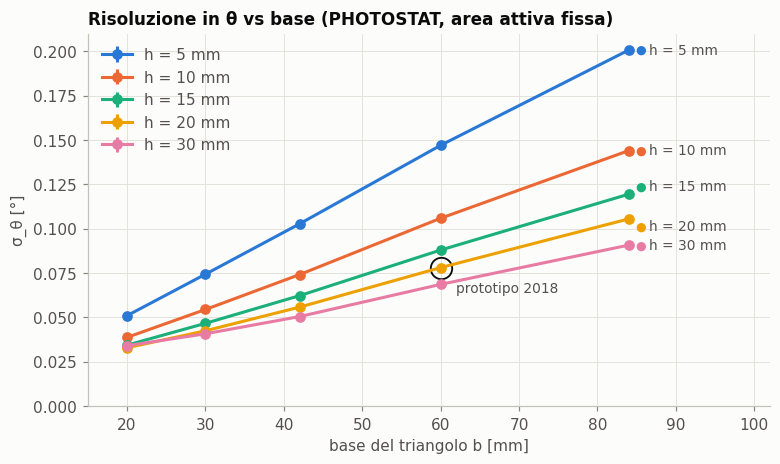

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, h in enumerate(HEIGHTS):
    g = ph[ph.height_mm == h].sort_values("base_mm")
    ax.errorbar(g.base_mm, g.sigma_theta_deg, g.sigma_theta_err, fmt="o-", color=sp.SERIES[i], ms=6, label=f"h = {h:.0f} mm")
    sp.end_label(ax, g.base_mm.iloc[-1], g.sigma_theta_deg.iloc[-1], f"h = {h:.0f} mm", sp.SERIES[i], dy=[0, 0, 5, -5, 0][i])
ax.plot(proto.base_mm, proto.sigma_theta_deg, "o", ms=14, mfc="none", mec=sp.INK, mew=1.2)
ax.annotate("prototipo 2018", (proto.base_mm, proto.sigma_theta_deg), xytext=(10, -16), textcoords="offset points",
            ha="left", color=sp.INK2, fontsize=9)
ax.set(xlim=(15, 102), ylim=(0, None), xlabel="base del triangolo b [mm]", ylabel="σ_θ [°]",
       title="Risoluzione in θ vs base (PHOTOSTAT, area attiva fissa)")
ax.legend(loc="upper left")
plt.show()

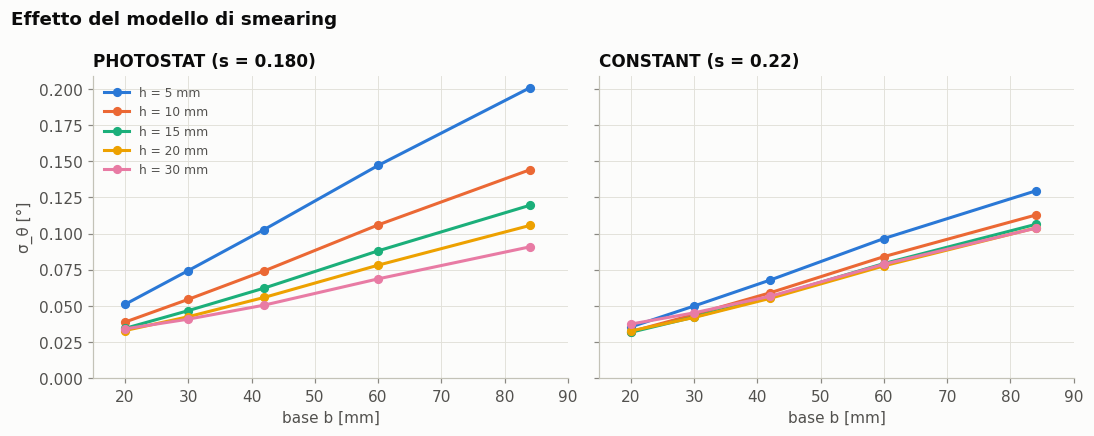

height_mm,5.0,10.0,15.0,20.0,30.0
base_mm,,,,,
20.0,1.441,1.206,1.084,1.008,0.911
30.0,1.490,1.238,1.104,1.012,0.903
42.0,1.515,1.256,1.111,1.012,0.892
60.0,1.523,1.260,1.110,1.006,0.871
84.0,1.550,1.277,1.124,1.017,0.875


In [4]:
# stessa figura per i due modelli di smearing, stessa scala
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, d) in zip(axs, (("PHOTOSTAT (s = 0.180)", ph), ("CONSTANT (s = 0.22)", co))):
    for i, h in enumerate(HEIGHTS):
        g = d[d.height_mm == h].sort_values("base_mm")
        ax.plot(g.base_mm, g.sigma_theta_deg, "o-", color=sp.SERIES[i], ms=5, label=f"h = {h:.0f} mm")
    ax.set(title=name, xlabel="base b [mm]", xlim=(15, 90), ylim=(0, None))
axs[0].set_ylabel("σ_θ [°]"); axs[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Effetto del modello di smearing", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
cmp = ph.merge(co, on=["base_mm", "height_mm"], suffixes=("_ph", "_co"))
cmp["PHOTOSTAT / CONSTANT"] = (cmp.sigma_theta_deg_ph / cmp.sigma_theta_deg_co).round(3)
cmp.pivot(index="base_mm", columns="height_mm", values="PHOTOSTAT / CONSTANT")

Con `CONSTANT` l'altezza conta poco (la risoluzione relativa in energia non dipende dal deposito). Con `PHOTOSTAT` le barre basse perdono molto: a h = 5 mm il deposito è ~4 volte più piccolo del prototipo e σ_E/E raddoppia.

## 3. σ_θ in funzione dell'altezza: esiste un'altezza ottimale?

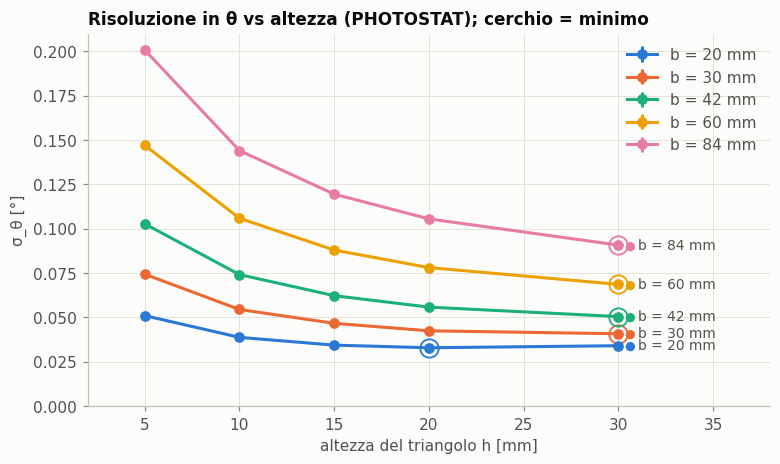

,base_mm,h ottimale [mm],σ_θ minimo [°]
27,20.0,20.0,0.032942
33,30.0,30.0,0.040831
38,42.0,30.0,0.050516
43,60.0,30.0,0.068671
48,84.0,30.0,0.090808


In [5]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, b in enumerate(BASES):
    g = ph[ph.base_mm == b].sort_values("height_mm")
    ax.errorbar(g.height_mm, g.sigma_theta_deg, g.sigma_theta_err, fmt="o-", color=sp.SERIES[i], ms=6, label=f"b = {b:.0f} mm")
    sp.end_label(ax, g.height_mm.iloc[-1], g.sigma_theta_deg.iloc[-1], f"b = {b:.0f} mm", sp.SERIES[i])
    k = g.sigma_theta_deg.idxmin()
    ax.plot(g.loc[k, "height_mm"], g.loc[k, "sigma_theta_deg"], "o", ms=12, mfc="none", mec=sp.SERIES[i], mew=1.2)
ax.set(xlim=(2, 38), ylim=(0, None), xlabel="altezza del triangolo h [mm]", ylabel="σ_θ [°]",
       title="Risoluzione in θ vs altezza (PHOTOSTAT); cerchio = minimo")
ax.legend(loc="upper right")
plt.show()
ph.loc[ph.groupby("base_mm").sigma_theta_deg.idxmin(), ["base_mm", "height_mm", "sigma_theta_deg"]].rename(
    columns={"height_mm": "h ottimale [mm]", "sigma_theta_deg": "σ_θ minimo [°]"})

Il compromesso: barre più alte depositano più energia (meglio per la fotostatistica, σ_E/E ∝ 1/√h) ma aumentano lo scattering multiplo e le fluttuazioni da raggi δ. Nella griglia:

* per **b ≥ 30 mm** la risoluzione migliora ancora da h = 20 a h = 30 mm (−4% a b = 30, −12% a b = 60): l'ottimo è oltre 30 mm, fuori dalla griglia;
* solo per **b = 20 mm** c'è un minimo, a h ≈ 20 mm: con barre strette lo scattering multiplo pesa di più;
* sotto 10–15 mm si perde molto: a h = 5 mm σ_θ è 1.5 (b = 20) – 1.9 (b = 84) volte quella a h = 20 mm.

## 4. Mappa della risoluzione

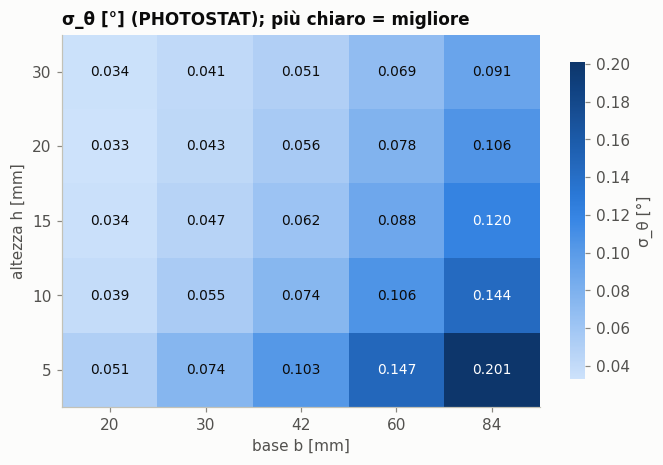

In [6]:
M = ph.pivot(index="height_mm", columns="base_mm", values="sigma_theta_deg")
fig, ax = plt.subplots(figsize=(7, 4.4))
im = ax.imshow(M.values, origin="lower", aspect="auto", cmap="sith_blue_r" if False else "sith_blue")
ax.set_xticks(range(len(M.columns)), [f"{b:.0f}" for b in M.columns])
ax.set_yticks(range(len(M.index)), [f"{h:.0f}" for h in M.index])
ax.grid(False)
vmax = np.nanmax(M.values)
for (i, j), v in np.ndenumerate(M.values):
    ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9, color="#ffffff" if v > 0.55 * vmax else sp.INK)
ax.set(xlabel="base b [mm]", ylabel="altezza h [mm]", title="σ_θ [°] (PHOTOSTAT); più chiaro = migliore")
cb = fig.colorbar(im, ax=ax, shrink=0.85); cb.outline.set_visible(False); cb.set_label("σ_θ [°]", color=sp.INK2)
plt.show()

## 5. Il costo: risoluzione contro numero di canali

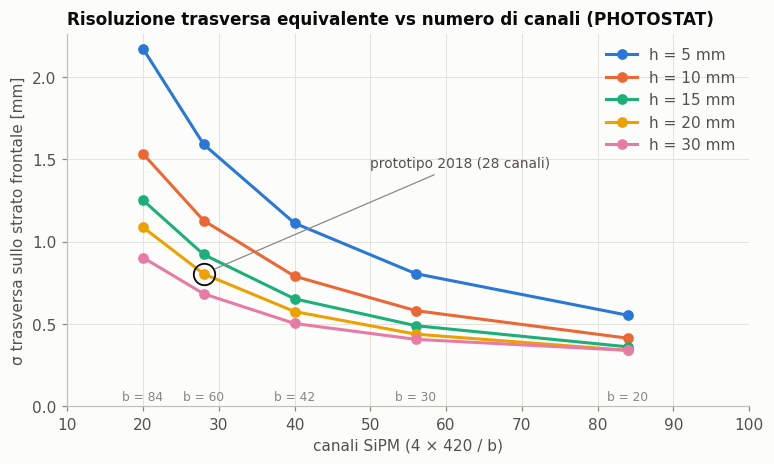

,base_mm,height_mm,channels,sigma_theta_deg,sigma_pos_mm,sigma_phi_A_deg,efficiency,miglioramento vs prototipo
27,20.0,20.0,84,0.032942,0.339217,0.032885,0.956636,2.37
28,20.0,30.0,84,0.034097,0.339211,0.032386,0.949252,2.29
26,20.0,15.0,84,0.034422,0.360464,0.035161,0.957024,2.27
25,20.0,10.0,84,0.038800,0.413088,0.040145,0.951838,2.01
33,30.0,30.0,56,0.040831,0.406203,0.040584,0.949014,1.91
32,30.0,20.0,56,0.042506,0.437707,0.044028,0.956980,1.84
31,30.0,15.0,56,0.046713,0.489175,0.048334,0.957710,1.67
38,42.0,30.0,40,0.050516,0.502556,0.051589,0.948976,1.55
29,20.0,5.0,84,0.051054,0.552462,0.053583,0.923910,1.53
30,30.0,10.0,56,0.054516,0.580403,0.056863,0.952282,1.43


In [7]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, h in enumerate(HEIGHTS):
    g = ph[ph.height_mm == h].sort_values("channels")
    ax.plot(g.channels, g.sigma_pos_mm, "o-", color=sp.SERIES[i], ms=6, label=f"h = {h:.0f} mm")
ax.plot(proto.channels, proto.sigma_pos_mm, "o", ms=14, mfc="none", mec=sp.INK, mew=1.2)
ax.annotate("prototipo 2018 (28 canali)", (proto.channels, proto.sigma_pos_mm), xytext=(50, 1.45), textcoords="data",
            color=sp.INK2, fontsize=9, arrowprops=dict(arrowstyle="-", color=sp.MUTED, lw=0.8, shrinkB=8))
for b in BASES:
    ax.annotate(f"b = {b:.0f}", (4 * 420 / b, 0), xytext=(0, 4), textcoords="offset points", ha="center", color=sp.MUTED, fontsize=8)
ax.set(xlim=(10, 100), ylim=(0, None), xlabel="canali SiPM (4 × 420 / b)", ylabel="σ trasversa sullo strato frontale [mm]",
       title="Risoluzione trasversa equivalente vs numero di canali (PHOTOSTAT)")
ax.legend(loc="upper right")
plt.show()
best = ph.copy()
best["miglioramento vs prototipo"] = (proto.sigma_theta_deg / best.sigma_theta_deg).round(2)
best.sort_values("sigma_theta_deg")[["base_mm", "height_mm", "channels", "sigma_theta_deg", "sigma_pos_mm",
                                     "sigma_phi_A_deg", "efficiency", "miglioramento vs prototipo"]].head(10)

## 6. Risoluzione in φ ed efficienza

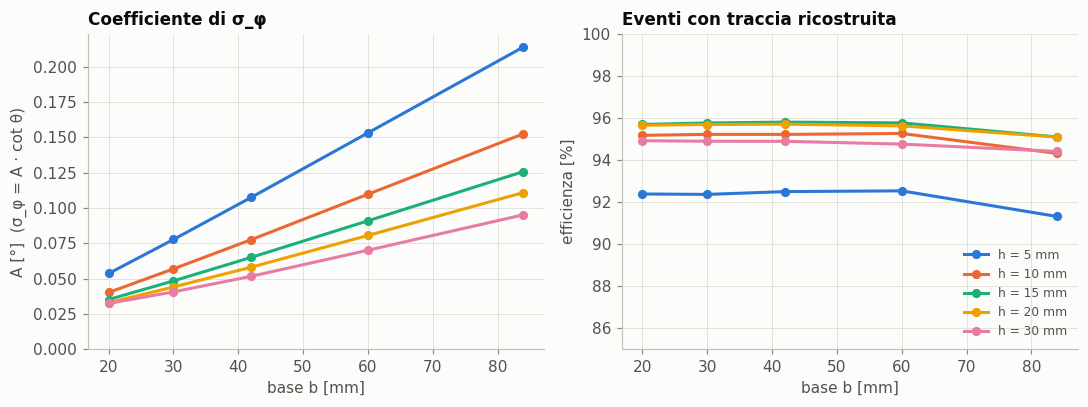

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for i, h in enumerate(HEIGHTS):
    g = ph[ph.height_mm == h].sort_values("base_mm")
    axs[0].plot(g.base_mm, g.sigma_phi_A_deg, "o-", color=sp.SERIES[i], ms=5, label=f"h = {h:.0f} mm")
    axs[1].plot(g.base_mm, 100 * g.efficiency, "o-", color=sp.SERIES[i], ms=5, label=f"h = {h:.0f} mm")
axs[0].set(xlabel="base b [mm]", ylabel="A [°]  (σ_φ = A · cot θ)", title="Coefficiente di σ_φ", ylim=(0, None))
axs[1].set(xlabel="base b [mm]", ylabel="efficienza [%]", title="Eventi con traccia ricostruita", ylim=(85, 100))
axs[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

L'efficienza (~95%) è limitata soprattutto dagli angoli del foro centrale a θ basso (stessa per tutte le geometrie) e scende di qualche punto per le barre più sottili, dove più depositi finiscono sotto la soglia di 35 keV vicino ai vertici.

## 7. Distribuzioni dei residui per tre geometrie

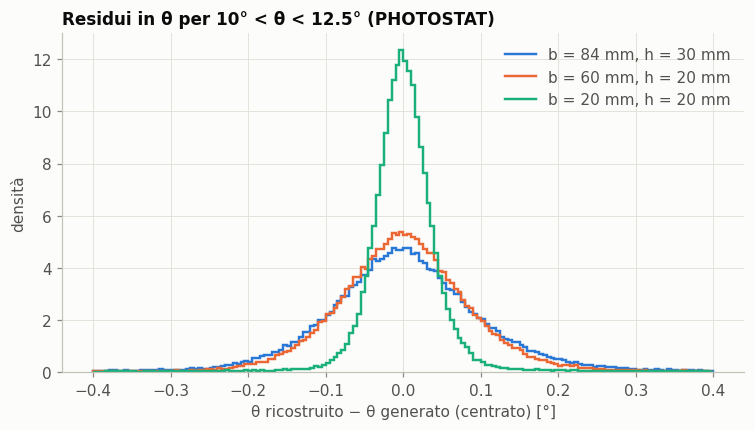

In [9]:
def residuals(b, h):
    d = R / "photostat" / f"b{b}_h{h}"
    geom = sr.Geometry.from_config(d / "config_last.cfg")
    F, B, gen = sr.load(sr.run_files(str(d / "output" / "*MeV_t*-{run}.root"), 0), geom)
    rec = sr.reconstruct(F, B, geom)
    tg = np.degrees(gen["theta_lab"])
    m = (tg > 10) & (tg < 12.5)
    return (rec["theta"] - tg)[m]

fig, ax = plt.subplots(figsize=(8, 4))
for i, (b, h) in enumerate(((84, 30), (60, 20), (20, 20))):
    r = residuals(b, h)
    r = r[np.isfinite(r)]
    sp.hist_line(ax, r - np.median(r), 160, (-0.4, 0.4), sp.SERIES[i], label=f"b = {b} mm, h = {h} mm", density=True)
ax.set(xlabel="θ ricostruito − θ generato (centrato) [°]", ylabel="densità",
       title="Residui in θ per 10° < θ < 12.5° (PHOTOSTAT)")
ax.legend(loc="upper right")
plt.show()

## 8. Conclusioni e limiti

* Con area attiva fissa la risoluzione angolare è dominata dalla **base**: da 60 a 30 mm (h = 20) σ_θ passa da 0.078° a 0.043° (×1.8), al prezzo di raddoppiare i canali (28 → 56). La dipendenza è circa lineare con un termine costante (scattering multiplo, dimensione del fascio).
* L'**altezza** conta tramite la fotostatistica: rispetto a h = 20 mm, barre da 10 mm perdono un fattore 1.2–1.4 e barre da 5 mm 1.5–1.9; da 20 a 30 mm si guadagna ancora il 4–14% per b ≥ 30 mm, mentre per b = 20 mm l'ottimo è a ~20 mm.
* Migliori compromessi nella griglia: **b = 30, h = 30** (0.041°, ×1.9 rispetto al prototipo, 56 canali); **b = 42, h = 30** (0.051°, ×1.55, 40 canali); **b = 20, h = 20** (0.033°, ×2.4, 84 canali).
* Per capire fin dove conviene alzare le barre servirebbe estendere la griglia a h = 40–50 mm per b ≥ 30 mm, tenendo conto del materiale davanti ai LYSO (punto 4 sotto).

**Limiti da tenere presenti prima di trarre conclusioni di design:**

1. Resa in luce per MeV uguale per tutte le geometrie: barre di sezione più piccola sarebbero meglio coperte dal SiPM 6×6 mm² e raccoglierebbero più luce → lo scan è *conservativo* per le barre piccole. L'attenuazione lungo la barra non è simulata.
2. La taratura dello smearing usa un solo punto (geometria del prototipo, test beam 2018).
3. La ricostruzione usa il passo nominale b invece di b + 2·(spessore alluminio): bias in θ dello 0.1–0.4% (corretto nel fit, non influisce su σ).
4. Solo deutoni da 270 MeV senza bersaglio: nessun fondo da scattering anelastico. Barre più alte significano più plastica davanti al calorimetro (perdita di energia, interazioni nucleari, peggior risoluzione in energia dei LYSO): questo costo non è nella metrica e limita l'altezza utile.
5. σ_θ qui viene dai residui con θ uniforme; sul prototipo lo scan a θ fisso dà 0.079° (media dei fit) contro 0.078° di questo metodo.